# ConsenDxFormer vs LungDxFormer
## Actual code • same nodule images • clear results

This notebook compares the LungDxFormer and ConsenDxFormer Architecture and performance comparison on the same lung nodules.


In [9]:
'''# loads the tools, tells the notebook 
where the project is, names the 3 classes, and lists the 3 training runs.

# IMPORTANT: it does NOT train or test a model.
'''
from pathlib import Path
import ast, json, hashlib, html, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
PROJECT = Path('/experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/03_ConsenDxFormer_and_Datasets/ConsenDxFormer')
SEEDS = (42,43,44)
CLASSES = ('benign','indeterminate','malignant')
IDS = ['patient_id','series_instance_uid','nodule_id']
RUN_IDS = {
'B1': {42:'phase3-b1-s42-67d865cd9ff05a4c',43:'phase3-b1-s43-7947651595ca43ab',44:'phase3-b1-s44-be7454203e5b8aa0'},
'ConsenDxFormer': {42:'phase4-final-s42-c1e650d77585ed9c',43:'phase4-final-s43-946220804796df93',44:'phase4-final-s44-8c74c3dd1e666bb5'}}
assert PROJECT.is_dir(), 'Run this notebook on the university server.'

def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()

COLORS={'B1':'#4676AD','ConsenDxFormer':'#008B80'}
NAMES={'B1':'LungDxFormer','ConsenDxFormer':'ConsenDxFormer'}
plt.rcParams.update({'figure.facecolor':'white','axes.facecolor':'white','font.size':12,
                     'axes.spines.top':False,'axes.spines.right':False})
def card(title,text,color='#123C50'):
    display(HTML(f'<div style="margin:22px 0;padding:20px 24px;border-left:6px solid {color};background:#F2F7F8;border-radius:8px"><h3 style="margin:0 0 12px;color:{color}">{html.escape(title)}</h3><div style="font-size:17px;line-height:1.65">{html.escape(text)}</div></div>'))
def nice_table(frame,title,caption=''):
    safe=frame.to_html(index=False,escape=True,border=0)
    display(HTML('<div style="margin:28px 0 38px"><h3>'+html.escape(title)+'</h3><style>.demo-table table{border-collapse:collapse;width:100%;font-size:16px}.demo-table th{background:#123C50;color:white;padding:16px;text-align:left}.demo-table td{padding:16px;border-bottom:1px solid #DCE6EA;text-align:left}.demo-table tr:nth-child(even){background:#F2F7F8}</style><div class="demo-table">'+safe+'</div><p style="line-height:1.6">'+html.escape(caption)+'</p></div>'))

## 1. What changed in the code?

**CNN:** Looks at the CT nodule and finds important image patterns. LungDxFormer mainly uses the deepest CNN features, while ConsenDxFormer keeps features from three CNN levels so it can use both fine details and deeper information..

**Transformer:** Connects information from different parts of the lung nodule, helping the model understand how features in one area relate to features in another area.

**Hierarchical fusion:** LungDxFormer B1 mainly combines its selected features by concatenating them together, while ConsenDxFormer combines deep, middle, and finer CNN features step by step. At each step, a learned gate controls how much additional detail should be included. This helps ConsenDxFormer preserve useful information from different feature levels, such as the shape, texture, and boundary of a lung nodule.

In [10]:
'''# keeps the actual model source code as text so the notebook can compare what
LungDxFormer and ConsenDxFormer are built from.

# IMPORTANT: Saving the code here does NOT run, train, or make predictions
with either model.
'''
SOURCES = {'baseline_model': 'from __future__ import annotations\nimport math\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nfrom lungdxformer.models.cnn_encoder import CNNEncoder\nfrom lungdxformer.models.positional_encoding import LearnablePositionalEncoding\nfrom lungdxformer.models.transformer_encoder import TransformerEncoder\nfrom lungdxformer.models.spatial_attention import DynamicSpatialAttention\nfrom lungdxformer.models.fusion import FeatureFusion\nfrom lungdxformer.models.classifier_head import ClassificationHead\n\nclass LungDxFormer(nn.Module):\n    def __init__(\n        self,\n        image_size: int = 96,\n        in_channels: int = 1,\n        num_classes: int = 3,\n        cnn_channels=(32, 64, 128),\n        embed_dim: int = 128,\n        transformer_heads: int = 4,\n        transformer_layers: int = 2,\n        transformer_mlp_ratio: float = 4.0,\n        dropout: float = 0.2,\n        use_transformer: bool = True,\n        use_positional_encoding: bool = True,\n        use_spatial_attention: bool = True,\n        fusion_type: str = "concat",\n        use_raw_transformer_in_fusion: bool = False,\n        classifier_hidden_dim: int = 128,\n    ):\n        super().__init__()\n        self.image_size = image_size\n        self.use_transformer = use_transformer\n        self.use_positional_encoding = use_positional_encoding\n        self.use_spatial_attention = use_spatial_attention\n\n        self.cnn_encoder = CNNEncoder(in_channels=in_channels, channels=cnn_channels)\n        cnn_out = self.cnn_encoder.out_channels\n        self.token_proj = nn.Conv2d(cnn_out, embed_dim, kernel_size=1)\n\n        reduced_h = image_size // (2 ** len(cnn_channels))\n        reduced_w = image_size // (2 ** len(cnn_channels))\n        self.num_tokens = reduced_h * reduced_w\n\n        self.positional_encoding = LearnablePositionalEncoding(max_tokens=self.num_tokens, embed_dim=embed_dim)\n        self.transformer = TransformerEncoder(\n            embed_dim=embed_dim,\n            num_heads=transformer_heads,\n            num_layers=transformer_layers,\n            mlp_ratio=transformer_mlp_ratio,\n            dropout=dropout,\n        )\n        self.dynamic_attention = DynamicSpatialAttention(embed_dim=embed_dim)\n        self.fusion = FeatureFusion(\n            cnn_channels=embed_dim,\n            trans_channels=embed_dim,\n            fusion_type=fusion_type,\n            use_raw_transformer=use_raw_transformer_in_fusion,\n        )\n        self.classifier = ClassificationHead(\n            in_channels=self.fusion.out_channels,\n            hidden_dim=classifier_hidden_dim,\n            num_classes=num_classes,\n            dropout=dropout,\n        )\n\n        self._last_feature_map = None\n\n    def _to_tokens(self, x_2d: torch.Tensor) -> tuple[torch.Tensor, tuple[int, int]]:\n        b, c, h, w = x_2d.shape\n        tokens = x_2d.flatten(2).transpose(1, 2)  # [B, N, C]\n        return tokens, (h, w)\n\n    def _to_2d(self, tokens: torch.Tensor, spatial_hw: tuple[int, int]) -> torch.Tensor:\n        b, n, c = tokens.shape\n        h, w = spatial_hw\n        return tokens.transpose(1, 2).reshape(b, c, h, w)\n\n    def forward(self, x: torch.Tensor) -> dict[str, torch.Tensor]:\n        cnn_local = self.cnn_encoder(x)\n        cnn_proj = self.token_proj(cnn_local)\n        tokens, spatial_hw = self._to_tokens(cnn_proj)\n\n        if self.use_positional_encoding:\n            tokens = self.positional_encoding(tokens)\n\n        if self.use_transformer:\n            trans_tokens = self.transformer(tokens)\n        else:\n            trans_tokens = tokens\n\n        trans_2d = self._to_2d(trans_tokens, spatial_hw)\n\n        if self.use_spatial_attention:\n            attn_feat, attn_map = self.dynamic_attention(trans_2d)\n        else:\n            attn_feat = trans_2d\n            attn_map = torch.ones(trans_2d.shape[0], 1, trans_2d.shape[2], trans_2d.shape[3], device=trans_2d.device)\n\n        fused = self.fusion(cnn_proj, attn_feat, trans_2d)\n        logits, pooled = self.classifier(fused)\n        probs = F.softmax(logits, dim=1)\n\n        self._last_feature_map = fused\n\n        return {\n            "logits": logits,\n            "probs": probs,\n            "attention_map": attn_map,\n            "cnn_features": cnn_proj,\n            "transformer_features": trans_2d,\n            "attention_features": attn_feat,\n            "fused_features": fused,\n            "pooled_features": pooled,\n        }\n\n    @property\n    def last_feature_map(self):\n        return self._last_feature_map\n', 'baseline_cnn': 'from __future__ import annotations\nimport torch\nimport torch.nn as nn\n\nclass ConvBlock(nn.Module):\n    def __init__(self, in_ch: int, out_ch: int):\n        super().__init__()\n        self.block = nn.Sequential(\n            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),\n            nn.BatchNorm2d(out_ch),\n            nn.ReLU(inplace=True),\n            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),\n            nn.BatchNorm2d(out_ch),\n            nn.ReLU(inplace=True),\n            nn.MaxPool2d(kernel_size=2),\n        )\n\n    def forward(self, x):\n        return self.block(x)\n\nclass CNNEncoder(nn.Module):\n    def __init__(self, in_channels: int = 1, channels=(32, 64, 128)):\n        super().__init__()\n        layers = []\n        prev = in_channels\n        for ch in channels:\n            layers.append(ConvBlock(prev, ch))\n            prev = ch\n        self.encoder = nn.Sequential(*layers)\n        self.out_channels = channels[-1]\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        return self.encoder(x)\n', 'baseline_transformer': 'from __future__ import annotations\nimport torch\nimport torch.nn as nn\n\nclass TransformerEncoderBlock(nn.Module):\n    def __init__(self, embed_dim: int, num_heads: int, mlp_ratio: float = 4.0, dropout: float = 0.1):\n        super().__init__()\n        self.norm1 = nn.LayerNorm(embed_dim)\n        self.attn = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads, dropout=dropout, batch_first=True)\n        self.drop1 = nn.Dropout(dropout)\n\n        hidden_dim = int(embed_dim * mlp_ratio)\n        self.norm2 = nn.LayerNorm(embed_dim)\n        self.mlp = nn.Sequential(\n            nn.Linear(embed_dim, hidden_dim),\n            nn.GELU(),\n            nn.Dropout(dropout),\n            nn.Linear(hidden_dim, embed_dim),\n            nn.Dropout(dropout),\n        )\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        residual = x\n        x = self.norm1(x)\n        x, _ = self.attn(x, x, x, need_weights=False)\n        x = residual + self.drop1(x)\n        x = x + self.mlp(self.norm2(x))\n        return x\n\nclass TransformerEncoder(nn.Module):\n    def __init__(self, embed_dim: int, num_heads: int, num_layers: int, mlp_ratio: float = 4.0, dropout: float = 0.1):\n        super().__init__()\n        self.layers = nn.ModuleList([\n            TransformerEncoderBlock(embed_dim, num_heads, mlp_ratio, dropout)\n            for _ in range(num_layers)\n        ])\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        for blk in self.layers:\n            x = blk(x)\n        return x\n', 'baseline_fusion': 'from __future__ import annotations\nimport torch\nimport torch.nn as nn\n\nclass FeatureFusion(nn.Module):\n    def __init__(self, cnn_channels: int, trans_channels: int, fusion_type: str = "concat", use_raw_transformer: bool = False):\n        super().__init__()\n        self.fusion_type = fusion_type\n        self.use_raw_transformer = use_raw_transformer\n\n        if fusion_type not in {"concat", "sum", "gated"}:\n            raise ValueError("fusion_type must be one of: concat, sum, gated")\n\n        if fusion_type == "concat":\n            in_ch = cnn_channels + trans_channels + (trans_channels if use_raw_transformer else 0)\n            self.proj = nn.Sequential(\n                nn.Conv2d(in_ch, trans_channels, kernel_size=1, bias=False),\n                nn.BatchNorm2d(trans_channels),\n                nn.ReLU(inplace=True),\n            )\n            self.out_channels = trans_channels\n\n        elif fusion_type == "sum":\n            self.align_cnn = nn.Conv2d(cnn_channels, trans_channels, kernel_size=1)\n            self.out_channels = trans_channels\n\n        else:  # gated\n            self.align_cnn = nn.Conv2d(cnn_channels, trans_channels, kernel_size=1)\n            gate_in = trans_channels * (2 + int(use_raw_transformer))\n            self.gate = nn.Sequential(\n                nn.Conv2d(gate_in, trans_channels, kernel_size=1),\n                nn.Sigmoid()\n            )\n            self.out_channels = trans_channels\n\n    def forward(self, cnn_feat: torch.Tensor, attn_feat: torch.Tensor, raw_transformer_feat: torch.Tensor | None = None) -> torch.Tensor:\n        if self.fusion_type == "concat":\n            feats = [cnn_feat, attn_feat]\n            if self.use_raw_transformer and raw_transformer_feat is not None:\n                feats.append(raw_transformer_feat)\n            x = torch.cat(feats, dim=1)\n            return self.proj(x)\n\n        if self.fusion_type == "sum":\n            return self.align_cnn(cnn_feat) + attn_feat\n\n        cnn_aligned = self.align_cnn(cnn_feat)\n        parts = [cnn_aligned, attn_feat]\n        if self.use_raw_transformer and raw_transformer_feat is not None:\n            parts.append(raw_transformer_feat)\n        cat = torch.cat(parts, dim=1)\n        gate = self.gate(cat)\n        return gate * cnn_aligned + (1 - gate) * attn_feat\n', 'consendxformer': '"""ConsenDxFormer Phase 4 model.\n\nThe model preserves the validated 2D LungDxFormer backbone scale and\nTransformer capacity while adding:\n- explicit C1/C2/C3 feature outputs,\n- native spatial-softmax attention,\n- hierarchical coarse-to-fine gated residual fusion,\n- a primary 3-class head,\n- a four-threshold ordinal auxiliary head.\n\nNo code in the locked external LungDxFormer checkout is modified.\n"""\n\nfrom __future__ import annotations\n\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\n\n\nclass ConvStage(nn.Module):\n    """Two convolutions followed by 2x downsampling, matching the baseline style."""\n\n    def __init__(self, in_channels: int, out_channels: int) -> None:\n        super().__init__()\n        self.block = nn.Sequential(\n            nn.Conv2d(\n                in_channels,\n                out_channels,\n                kernel_size=3,\n                padding=1,\n                bias=False,\n            ),\n            nn.BatchNorm2d(out_channels),\n            nn.ReLU(inplace=True),\n            nn.Conv2d(\n                out_channels,\n                out_channels,\n                kernel_size=3,\n                padding=1,\n                bias=False,\n            ),\n            nn.BatchNorm2d(out_channels),\n            nn.ReLU(inplace=True),\n            nn.MaxPool2d(kernel_size=2),\n        )\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        return self.block(x)\n\n\nclass MultiScaleCNNEncoder(nn.Module):\n    """Return all three CNN scales required for hierarchical fusion."""\n\n    def __init__(\n        self,\n        in_channels: int,\n        channels: tuple[int, int, int],\n    ) -> None:\n        super().__init__()\n\n        if len(channels) != 3:\n            raise ValueError("cnn_channels must contain exactly three stages")\n\n        c1, c2, c3 = channels\n\n        self.stage1 = ConvStage(in_channels, c1)\n        self.stage2 = ConvStage(c1, c2)\n        self.stage3 = ConvStage(c2, c3)\n\n        self.channels = channels\n\n    def forward(\n        self,\n        x: torch.Tensor,\n    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:\n        c1 = self.stage1(x)\n        c2 = self.stage2(c1)\n        c3 = self.stage3(c2)\n        return c1, c2, c3\n\n\nclass LearnablePositionalEncoding(nn.Module):\n    def __init__(self, max_tokens: int, embed_dim: int) -> None:\n        super().__init__()\n        if max_tokens <= 0:\n            raise ValueError("max_tokens must be positive")\n        self.position = nn.Parameter(\n            torch.zeros(1, max_tokens, embed_dim)\n        )\n        nn.init.trunc_normal_(self.position, std=0.02)\n\n    def forward(self, tokens: torch.Tensor) -> torch.Tensor:\n        if tokens.ndim != 3:\n            raise ValueError("tokens must have shape [B, N, C]")\n        if tokens.shape[1] > self.position.shape[1]:\n            raise ValueError(\n                "Input contains more tokens than positional encoding supports"\n            )\n        return tokens + self.position[:, : tokens.shape[1]]\n\n\nclass TransformerEncoderBlock(nn.Module):\n    def __init__(\n        self,\n        embed_dim: int,\n        num_heads: int,\n        mlp_ratio: float,\n        dropout: float,\n    ) -> None:\n        super().__init__()\n\n        self.norm1 = nn.LayerNorm(embed_dim)\n        self.attention = nn.MultiheadAttention(\n            embed_dim=embed_dim,\n            num_heads=num_heads,\n            dropout=dropout,\n            batch_first=True,\n        )\n        self.dropout1 = nn.Dropout(dropout)\n\n        hidden_dim = int(embed_dim * mlp_ratio)\n\n        self.norm2 = nn.LayerNorm(embed_dim)\n        self.mlp = nn.Sequential(\n            nn.Linear(embed_dim, hidden_dim),\n            nn.GELU(),\n            nn.Dropout(dropout),\n            nn.Linear(hidden_dim, embed_dim),\n            nn.Dropout(dropout),\n        )\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        residual = x\n        normalized = self.norm1(x)\n\n        attended, _ = self.attention(\n            normalized,\n            normalized,\n            normalized,\n            need_weights=False,\n        )\n\n        x = residual + self.dropout1(attended)\n        x = x + self.mlp(self.norm2(x))\n\n        return x\n\n\nclass TransformerEncoder(nn.Module):\n    def __init__(\n        self,\n        embed_dim: int,\n        num_heads: int,\n        num_layers: int,\n        mlp_ratio: float,\n        dropout: float,\n    ) -> None:\n        super().__init__()\n\n        if num_layers <= 0:\n            raise ValueError("transformer_layers must be positive")\n\n        self.layers = nn.ModuleList(\n            [\n                TransformerEncoderBlock(\n                    embed_dim=embed_dim,\n                    num_heads=num_heads,\n                    mlp_ratio=mlp_ratio,\n                    dropout=dropout,\n                )\n                for _ in range(num_layers)\n            ]\n        )\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        for layer in self.layers:\n            x = layer(x)\n        return x\n\n\nclass DynamicSpatialAttention(nn.Module):\n    """Native LungDxFormer-style spatial-softmax attention."""\n\n    def __init__(self, embed_dim: int) -> None:\n        super().__init__()\n        self.projection = nn.Conv2d(\n            embed_dim,\n            1,\n            kernel_size=1,\n        )\n\n    def forward(\n        self,\n        feature_map: torch.Tensor,\n    ) -> tuple[torch.Tensor, torch.Tensor]:\n        logits = self.projection(feature_map)\n\n        batch, _, height, width = logits.shape\n\n        attention = F.softmax(\n            logits.reshape(batch, 1, height * width),\n            dim=-1,\n        ).reshape(\n            batch,\n            1,\n            height,\n            width,\n        )\n\n        weighted = feature_map * attention\n\n        return weighted, attention\n\n\nclass DeepFusion(nn.Module):\n    """Baseline-like deepest-scale CNN/attention fusion."""\n\n    def __init__(\n        self,\n        cnn_channels: int,\n        embed_dim: int,\n    ) -> None:\n        super().__init__()\n\n        self.cnn_projection = nn.Conv2d(\n            cnn_channels,\n            embed_dim,\n            kernel_size=1,\n        )\n\n        self.fusion = nn.Sequential(\n            nn.Conv2d(\n                embed_dim * 2,\n                embed_dim,\n                kernel_size=1,\n                bias=False,\n            ),\n            nn.BatchNorm2d(embed_dim),\n            nn.ReLU(inplace=True),\n        )\n\n    def forward(\n        self,\n        c3: torch.Tensor,\n        attention_features: torch.Tensor,\n    ) -> torch.Tensor:\n        projected_c3 = self.cnn_projection(c3)\n        return self.fusion(\n            torch.cat(\n                [projected_c3, attention_features],\n                dim=1,\n            )\n        )\n\n\nclass GatedResidualFusion(nn.Module):\n    """Inject a finer CNN scale into an upsampled deeper representation."""\n\n    def __init__(\n        self,\n        lateral_channels: int,\n        embed_dim: int,\n    ) -> None:\n        super().__init__()\n\n        self.lateral_projection = nn.Sequential(\n            nn.Conv2d(\n                lateral_channels,\n                embed_dim,\n                kernel_size=1,\n                bias=False,\n            ),\n            nn.BatchNorm2d(embed_dim),\n            nn.ReLU(inplace=True),\n        )\n\n        self.gate = nn.Sequential(\n            nn.Conv2d(\n                embed_dim * 2,\n                embed_dim,\n                kernel_size=1,\n            ),\n            nn.Sigmoid(),\n        )\n\n        self.refine = nn.Sequential(\n            nn.Conv2d(\n                embed_dim,\n                embed_dim,\n                kernel_size=3,\n                padding=1,\n                bias=False,\n            ),\n            nn.BatchNorm2d(embed_dim),\n            nn.ReLU(inplace=True),\n        )\n\n    def forward(\n        self,\n        deep_feature: torch.Tensor,\n        lateral_feature: torch.Tensor,\n    ) -> torch.Tensor:\n        upsampled = F.interpolate(\n            deep_feature,\n            size=lateral_feature.shape[-2:],\n            mode="bilinear",\n            align_corners=False,\n        )\n\n        lateral = self.lateral_projection(\n            lateral_feature\n        )\n\n        gate = self.gate(\n            torch.cat(\n                [upsampled, lateral],\n                dim=1,\n            )\n        )\n\n        # Residual preservation of the deeper semantic representation,\n        # with gated injection of the finer spatial feature.\n        fused = upsampled + gate * lateral\n\n        return self.refine(fused)\n\n\nclass ConsenDxFormer(nn.Module):\n    """Disagreement-aware 2D CNN-Transformer for pulmonary nodules."""\n\n    def __init__(\n        self,\n        *,\n        image_size: int = 64,\n        in_channels: int = 1,\n        num_classes: int = 3,\n        cnn_channels: tuple[int, int, int] = (32, 64, 128),\n        embed_dim: int = 128,\n        transformer_heads: int = 4,\n        transformer_layers: int = 2,\n        transformer_mlp_ratio: float = 4.0,\n        dropout: float = 0.5,\n        classifier_hidden_dim: int = 128,\n        use_positional_encoding: bool = True,\n        use_spatial_attention: bool = True,\n        use_hierarchical_fusion: bool = True,\n    ) -> None:\n        super().__init__()\n\n        if image_size <= 0 or image_size % 8 != 0:\n            raise ValueError(\n                "image_size must be positive and divisible by 8"\n            )\n\n        if num_classes != 3:\n            raise ValueError(\n                "ConsenDxFormer primary head is locked to three classes"\n            )\n\n        if len(cnn_channels) != 3:\n            raise ValueError(\n                "cnn_channels must contain exactly three values"\n            )\n\n        if embed_dim <= 0:\n            raise ValueError("embed_dim must be positive")\n\n        if embed_dim % transformer_heads != 0:\n            raise ValueError(\n                "embed_dim must be divisible by transformer_heads"\n            )\n\n        self.image_size = int(image_size)\n        self.embed_dim = int(embed_dim)\n\n        self.use_positional_encoding = bool(\n            use_positional_encoding\n        )\n        self.use_spatial_attention = bool(\n            use_spatial_attention\n        )\n        self.use_hierarchical_fusion = bool(\n            use_hierarchical_fusion\n        )\n\n        self.encoder = MultiScaleCNNEncoder(\n            in_channels=in_channels,\n            channels=cnn_channels,\n        )\n\n        deepest_channels = cnn_channels[-1]\n\n        self.token_projection = nn.Conv2d(\n            deepest_channels,\n            embed_dim,\n            kernel_size=1,\n        )\n\n        deep_size = image_size // 8\n        number_of_tokens = deep_size * deep_size\n\n        self.positional_encoding = LearnablePositionalEncoding(\n            max_tokens=number_of_tokens,\n            embed_dim=embed_dim,\n        )\n\n        self.transformer = TransformerEncoder(\n            embed_dim=embed_dim,\n            num_heads=transformer_heads,\n            num_layers=transformer_layers,\n            mlp_ratio=transformer_mlp_ratio,\n            dropout=dropout,\n        )\n\n        self.dynamic_attention = DynamicSpatialAttention(\n            embed_dim=embed_dim,\n        )\n\n        self.deep_fusion = DeepFusion(\n            cnn_channels=deepest_channels,\n            embed_dim=embed_dim,\n        )\n\n        self.c2_fusion = GatedResidualFusion(\n            lateral_channels=cnn_channels[1],\n            embed_dim=embed_dim,\n        )\n\n        self.c1_fusion = GatedResidualFusion(\n            lateral_channels=cnn_channels[0],\n            embed_dim=embed_dim,\n        )\n\n        self.pool = nn.AdaptiveAvgPool2d(1)\n\n        self.classifier = nn.Sequential(\n            nn.Linear(\n                embed_dim,\n                classifier_hidden_dim,\n            ),\n            nn.ReLU(inplace=True),\n            nn.Dropout(dropout),\n            nn.Linear(\n                classifier_hidden_dim,\n                num_classes,\n            ),\n        )\n\n        self.ordinal_head = nn.Sequential(\n            nn.Linear(\n                embed_dim,\n                classifier_hidden_dim,\n            ),\n            nn.ReLU(inplace=True),\n            nn.Dropout(dropout),\n            nn.Linear(\n                classifier_hidden_dim,\n                4,\n            ),\n        )\n\n    @staticmethod\n    def _to_tokens(\n        feature_map: torch.Tensor,\n    ) -> tuple[torch.Tensor, tuple[int, int]]:\n        batch, channels, height, width = feature_map.shape\n\n        tokens = feature_map.flatten(2).transpose(1, 2)\n\n        return tokens, (height, width)\n\n    @staticmethod\n    def _to_feature_map(\n        tokens: torch.Tensor,\n        spatial_size: tuple[int, int],\n    ) -> torch.Tensor:\n        batch, token_count, channels = tokens.shape\n        height, width = spatial_size\n\n        if token_count != height * width:\n            raise ValueError(\n                "Token count disagrees with requested spatial shape"\n            )\n\n        return (\n            tokens.transpose(1, 2)\n            .reshape(\n                batch,\n                channels,\n                height,\n                width,\n            )\n        )\n\n    def forward(\n        self,\n        x: torch.Tensor,\n    ) -> dict[str, torch.Tensor]:\n        if x.ndim != 4:\n            raise ValueError(\n                "Input must have shape [B, C, H, W]"\n            )\n\n        c1, c2, c3 = self.encoder(x)\n\n        projected_c3 = self.token_projection(c3)\n\n        tokens, spatial_size = self._to_tokens(\n            projected_c3\n        )\n\n        if self.use_positional_encoding:\n            tokens = self.positional_encoding(tokens)\n\n        transformed_tokens = self.transformer(tokens)\n\n        transformer_features = self._to_feature_map(\n            transformed_tokens,\n            spatial_size,\n        )\n\n        if self.use_spatial_attention:\n            attention_features, attention_map = (\n                self.dynamic_attention(\n                    transformer_features\n                )\n            )\n        else:\n            batch, _, height, width = (\n                transformer_features.shape\n            )\n\n            attention_map = torch.full(\n                (\n                    batch,\n                    1,\n                    height,\n                    width,\n                ),\n                fill_value=1.0 / float(height * width),\n                device=transformer_features.device,\n                dtype=transformer_features.dtype,\n            )\n\n            attention_features = (\n                transformer_features * attention_map\n            )\n\n        deep_fused = self.deep_fusion(\n            c3,\n            attention_features,\n        )\n\n        if self.use_hierarchical_fusion:\n            fused_c2 = self.c2_fusion(\n                deep_fused,\n                c2,\n            )\n            fused = self.c1_fusion(\n                fused_c2,\n                c1,\n            )\n        else:\n            fused = deep_fused\n\n        pooled = self.pool(fused).flatten(1)\n\n        logits = self.classifier(pooled)\n        ordinal_logits = self.ordinal_head(pooled)\n\n        probabilities = F.softmax(\n            logits,\n            dim=1,\n        )\n\n        return {\n            "logits": logits,\n            "probs": probabilities,\n            "ordinal_logits": ordinal_logits,\n            "attention_map": attention_map,\n            "c1_features": c1,\n            "c2_features": c2,\n            "c3_features": c3,\n            "transformer_features": transformer_features,\n            "attention_features": attention_features,\n            "deep_fused_features": deep_fused,\n            "fused_features": fused,\n            "pooled_features": pooled,\n        }\n'}
model_path=PROJECT/'src/consendxformer/phase4_model.py'
assert sha(model_path)==hashlib.sha256(SOURCES['consendxformer'].encode()).hexdigest(), 'Model source differs; review it before presenting.'
def method_statements(source,class_name,method_name):
    cls=next(n for n in ast.parse(source).body if isinstance(n,ast.ClassDef) and n.name==class_name)
    method=next(n for n in cls.body if isinstance(n,ast.FunctionDef) and n.name==method_name)
    return method.body

def annotated(statements,notes):
    assert len(statements)==len(notes)
    lines=[]
    for statement,note in zip(statements,notes):
        # Formatting is compact; the expression comes from the actual reviewed source.
        lines.append(re.sub(r'\s+',' ',ast.unparse(statement)).strip()+'  # '+note)
    return '\n'.join(lines)

def compare_code(title,left,right):
    display(HTML('<div style="margin:28px 0 38px"><h3>'+html.escape(title)+'</h3><div style="display:flex;gap:22px">'+
     ''.join('<div style="flex:1;min-width:0;padding:18px;background:#F2F7F8;border-radius:8px"><h4>'+name+'</h4><pre style="font-size:13px;line-height:1.85;white-space:pre-wrap;overflow-wrap:anywhere">'+html.escape(value)+'</pre></div>'
             for name,value in [('LungDxFormer B1',left),('ConsenDxFormer',right)])+'</div></div>'))

b=method_statements(SOURCES['baseline_cnn'],'CNNEncoder','forward')
c=method_statements(SOURCES['consendxformer'],'MultiScaleCNNEncoder','forward')
compare_code('CNN — keeping detail from more levels',
 annotated(b,['Run all three CNN stages; return only their final output.']),
 annotated(c,['First stage keeps fine detail.','Second stage finds larger patterns.','Third stage finds deeper patterns.','Return all three levels so fusion can reuse fine detail.']))

b=method_statements(SOURCES['baseline_transformer'],'TransformerEncoderBlock','forward')
c=method_statements(SOURCES['consendxformer'],'TransformerEncoderBlock','forward')
compare_code('Transformer — the same core idea',
 annotated(b,['Keep the original features for a residual connection.','Normalize features before attention.','Let all crop locations exchange information.','Add attention to the original features.','Refine features and keep another residual connection.','Return the updated features.']),
 annotated(c,['Keep the original features; same residual idea.','Normalize features; same role as baseline.','Exchange information between crop locations; same attention operation.','Add attention to the original features; same structure.','Refine features with the same residual structure.','Return the updated features.']))

b=method_statements(SOURCES['baseline_model'],'LungDxFormer','forward')
c=method_statements(SOURCES['consendxformer'],'GatedResidualFusion','forward')
bfusion=next(n for n in b if isinstance(n,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='fused' for t in n.targets))
compare_code('Fusion — one deep level versus adding finer levels',
 annotated([bfusion],['B1 combines deep CNN and attention features at one level using concatenation.']),
 annotated(c,['Resize deeper features to the finer level.','Match the finer CNN features to the required channels.','Learn how much fine detail to add using a sigmoid gate.','Preserve deep information and add gated fine detail.','Refine the combined features.']))

forward=method_statements(SOURCES['consendxformer'],'ConsenDxFormer','forward')
hier=next(n for n in forward if isinstance(n,ast.If) and 'use_hierarchical_fusion' in ast.unparse(n.test))
compare_code('Two fusion steps in the complete model',
 annotated([bfusion],['The B1 forward path ends fusion at the deep feature level.']),
 annotated(hier.body,['Bring middle-level C2 detail into the deep representation.','Bring finer C1 detail into the result before classification.']))
card('What this change is intended to do','Keep small nodule details that may be lost when only the deepest CNN output is used. This is the design goal; the experiments decide whether it improves results.')

In [3]:
'''
# opens the saved test predictions and checks that they are genuine, 
complete, and matched correctly between the two models.

# IMPORTANT: The file hashes and IDs help prevent comparing the wrong files or 
different nodules.
'''
def run_dir(model,seed):
    base='phase3' if model=='B1' else 'phase4'
    return PROJECT/'artifacts'/base/'experiments'/RUN_IDS[model][seed]

def verified_read(directory,relative):
    marker=json.loads((directory/'COMPLETED.json').read_text())
    manifest_path=directory/'artifact_manifest.json'
    assert marker['artifact_manifest_sha256']==sha(manifest_path), 'Manifest binding mismatch'
    manifest=json.loads(manifest_path.read_text())
    assert manifest.get('experiment_id')==directory.name
    digest=manifest['files'][relative]
    if isinstance(digest,dict): digest=digest['sha256']
    path=directory/relative
    assert sha(path)==digest, 'File hash mismatch: '+str(path)
    return path

frames={}; metadata={}; joined={}
for seed in SEEDS:
    for model in RUN_IDS:
        d=run_dir(model,seed)
        f=pd.read_csv(verified_read(d,'predictions/test.csv'),dtype={k:str for k in IDS})
        assert len(f)==183 and f.patient_id.nunique()==99
        assert set(f.split)=={'test'} and set(pd.to_numeric(f.seed))=={seed}
        assert not f.duplicated(IDS).any()
        assert set(f.true_class)<=set(CLASSES) and set(f.predicted_class)<=set(CLASSES)
        p=f[['prob_'+c for c in CLASSES]].to_numpy(float)
        assert np.isfinite(p).all() and (p>=0).all() and (p<=1).all()
        assert np.allclose(p.sum(1),1,atol=1e-6)
        assert np.array_equal(np.array(CLASSES)[p.argmax(1)],f.predicted_class.to_numpy())
        frames[model,seed]=f
        rel='config/input_metadata.csv' if model=='B1' else 'config/input_supervision.csv'
        metadata[model,seed]=pd.read_csv(verified_read(d,rel),dtype={k:str for k in IDS})
    a,b=frames['B1',seed],frames['ConsenDxFormer',seed]
    j=a.merge(b,on=IDS,how='outer',suffixes=('_B1','_Consen'),validate='one_to_one',indicator=True)
    assert set(j['_merge'])=={'both'}
    assert (j.true_class_B1==j.true_class_Consen).all()
    assert (j.split_B1==j.split_Consen).all()
    assert (j.true_class_B1=='indeterminate').sum()==41
    joined[seed]=j.sort_values(IDS).reset_index(drop=True)
reference=joined[SEEDS[0]].sort_values(IDS)[IDS+["true_class_B1"]].reset_index(drop=True)
for seed in SEEDS[1:]:
    current=joined[seed].sort_values(IDS)[IDS+["true_class_B1"]].reset_index(drop=True)
    assert reference.equals(current), "Test membership or labels differ across seeds."


## 2. The key results — all three training runs

**Accuracy:** percentage of all test nodules classified correctly.

**Macro-F1:** balances performance across the three classes equally; this remains the main study score.

**Indeterminate recall:** how many of the 41 reference-indeterminate nodules were recognized. This is what “accuracy within the indeterminate class” usually means in this comparison.

**Indeterminate F1:** balances finding indeterminate cases with avoiding incorrect indeterminate predictions.

The table and the chart below both show the **mean across the same three training runs**.

---
This section compares the main scores from all three training runs. Accuracy asks, “How many total nodules were correct?” Macro-F1 gives the three classes equal importance. Indeterminate recall asks, “Of the truly indeterminate nodules, how many did the model find?” Indeterminate F1 also considers false alarms. **Example:** finding 30 of 41 indeterminate nodules is useful, but calling many benign nodules indeterminate by mistake also matters.


Model,Accuracy,Macro-F1,Indeterminate recall,Indeterminate F1
LungDxFormer,66.8%,67.2%,68.3%,50.6%
ConsenDxFormer,66.1%,66.8%,71.5%,50.6%


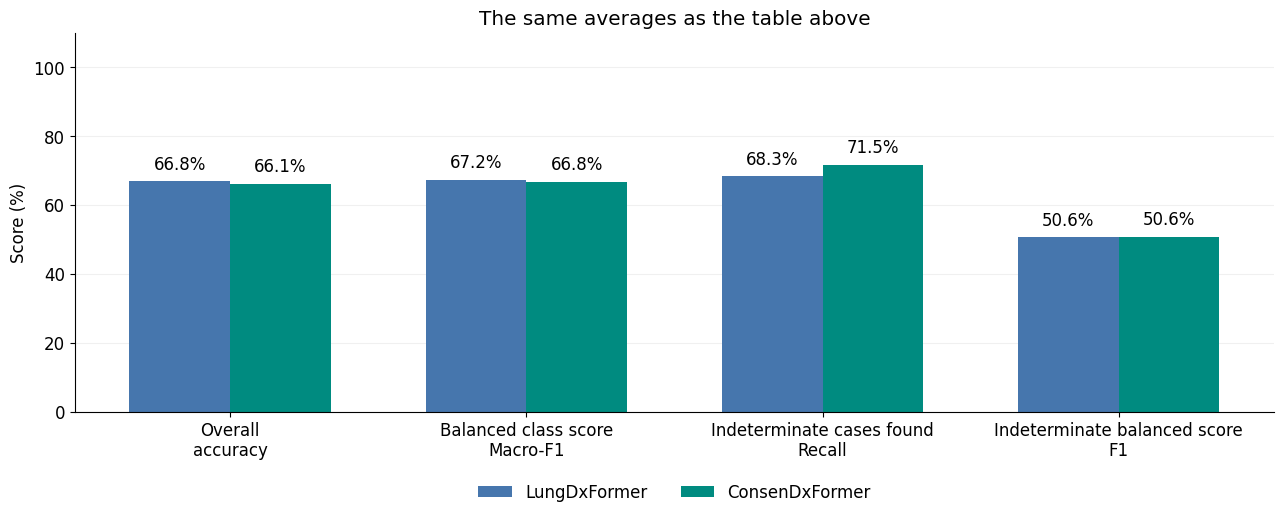

In [11]:
''''
# calculates the scores for each model and each training run, 
then averages the three runs and draws the comparison.
# Instead of judging a model from one lucky test, 
we look at seeds 42, 43, and 44 and ask how it performs on average.
# IMPORTANT: A higher number here is a descriptive result;
statistical superiority needs separate evidence.
'''
def class_scores(f):
    y=f.true_class.to_numpy(); p=f.predicted_class.to_numpy(); rows=[]
    for c in CLASSES:
        tp=int(((y==c)&(p==c)).sum()); fp=int(((y!=c)&(p==c)).sum()); fn=int(((y==c)&(p!=c)).sum())
        rows.append({'class':c,'correct':tp,'support':int((y==c).sum()),
            'precision':tp/(tp+fp) if tp+fp else 0.,'recall':tp/(tp+fn) if tp+fn else 0.,
            'f1':2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.})
    return pd.DataFrame(rows)

metrics=[]; per_class=[]
for seed in SEEDS:
    for model in RUN_IDS:
        f=frames[model,seed]; scores=class_scores(f)
        ind=scores[scores['class']=='indeterminate'].iloc[0]
        metrics.append({'model':model,'seed':seed,'Accuracy':float((f.true_class==f.predicted_class).mean()),
            'Macro-F1':scores.f1.mean(),'Indeterminate recall':ind.recall,'Indeterminate F1':ind.f1,
            'Indeterminate precision':ind.precision})
        per_class.extend(scores.assign(model=model,seed=seed).to_dict('records'))
metrics=pd.DataFrame(metrics); per_class=pd.DataFrame(per_class)
IMPORTANT=['Accuracy','Macro-F1','Indeterminate recall','Indeterminate F1']
summary=metrics.groupby('model')[IMPORTANT].mean().reindex(['B1','ConsenDxFormer'])
presentation=summary.mul(100).map(lambda v:f'{v:.1f}%') if hasattr(summary,'map') else summary.mul(100).applymap(lambda v:f'{v:.1f}%')
presentation.insert(0,'Model',[NAMES[m] for m in presentation.index])
nice_table(presentation.reset_index(drop=True),'Same test set · mean of three training runs','Higher is better. 183 test nodules per run; 41 belong to the indeterminate reference class. Repeated runs are not additional independent patients.')

fig,ax=plt.subplots(figsize=(13,5.4)); x=np.arange(len(IMPORTANT)); width=.34
for k,model in enumerate(['B1','ConsenDxFormer']):
    heights=summary.loc[model,IMPORTANT].to_numpy(float)*100
    bars=ax.bar(x+(k-.5)*width,heights,width,label=NAMES[model],color=COLORS[model])
    assert np.allclose([b.get_height() for b in bars],heights)  # Chart uses exactly the table values.
    ax.bar_label(bars,labels=[f'{v:.1f}%' for v in heights],padding=6,fontsize=12)
ax.set(xticks=x,xticklabels=['Overall\naccuracy','Balanced class score\nMacro-F1','Indeterminate cases found\nRecall','Indeterminate balanced score\nF1'],ylim=(0,110),ylabel='Score (%)',title='The same averages as the table above')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2,frameon=False)
ax.grid(axis='y',alpha=.18); ax.set_axisbelow(True); plt.tight_layout(); plt.show()

## 3. Why individual examples and average scores can look different

The following table makes the paired outcomes explicit.

A **seed** identifies one repeated training run. Every row below compares the same 41 indeterminate nodules, matched by patient, series and nodule ID.

---
One image can tell a different story from the overall result. A model may lose on one nodule but still perform better across many nodules. **Example:** one doctor can make one wrong diagnosis and still be more accurate across the full set of patients. That is why we compare the same nodules and also report the overall scores.


Training run (seed),Consen only: correct,Lung only: correct,Both correct,Both missed,Consen found / 41,Lung found / 41,Extra cases found by Consen
42,7,1,27,6,34,28,6
43,7,1,25,8,32,26,6
44,1,9,21,10,22,30,-8


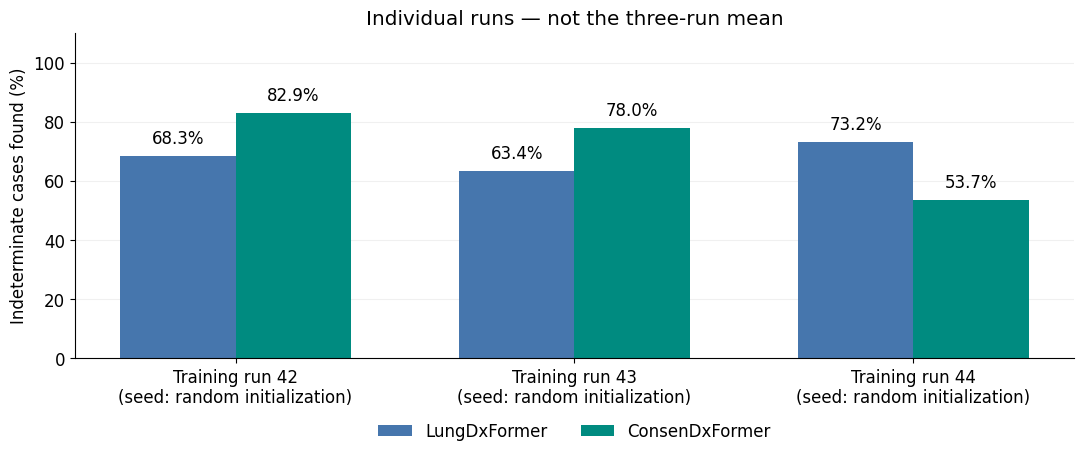

In [5]:
''''
# compares the same 41 indeterminate nodules one by one for each seed. 
It counts when only ConsenDxFormer is correct, only LungDxFormer is correct, 
both are correct, or both are wrong.

# IMPORTANT: This is a fair paired comparison because the nodule is the same
for both models.
''''
paired_counts=[]
for seed,j in joined.items():
    t=j[j.true_class_B1=='indeterminate']; a=t.predicted_class_B1=='indeterminate'; b=t.predicted_class_Consen=='indeterminate'
    both=int((a&b).sum()); cw=int(((~a)&b).sum()); bw=int((a&(~b)).sum()); neither=int(((~a)&(~b)).sum())
    assert both+cw+bw+neither==41
    paired_counts.append({'Training run (seed)':seed,'Consen only: correct':cw,'Lung only: correct':bw,
        'Both correct':both,'Both missed':neither,'Consen found / 41':both+cw,'Lung found / 41':both+bw,'Extra cases found by Consen':cw-bw})
counts=pd.DataFrame(paired_counts)
nice_table(counts,'Same 41 indeterminate nodules — who classified them correctly?',
 '“Consen only” means ConsenDxFormer was correct and LungDxFormer was wrong on that exact nodule. “Both missed” means both predicted another class.')

fig,ax=plt.subplots(figsize=(11,4.8)); x=np.arange(len(SEEDS)); width=.34
for k,model in enumerate(['B1','ConsenDxFormer']):
    rows=metrics[metrics.model==model].set_index('seed').loc[list(SEEDS)]
    values=rows['Indeterminate recall'].to_numpy()*100
    bars=ax.bar(x+(k-.5)*width,values,width,color=COLORS[model],label=NAMES[model])
    ax.bar_label(bars,labels=[f'{v:.1f}%' for v in values],padding=6)
ax.set(xticks=x,xticklabels=[f'Training run {s}\n(seed: random initialization)' for s in SEEDS],ylim=(0,110),ylabel='Indeterminate cases found (%)',title='Individual runs — not the three-run mean')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2,frameon=False); ax.grid(axis='y',alpha=.18); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

cw=int(counts['Consen only: correct'].sum()); bw=int(counts['Lung only: correct'].sum())
card('What the paired results show',f'Across the three runs, ConsenDxFormer alone is correct in {cw} case-run observations, while LungDxFormer alone is correct in {bw}. These are repeated observations of the same nodules, not {cw+bw} independent patients. Benefits may differ between runs.')

## 4. Same-image comparison — one selected training run

This section chooses one training run only to show image examples.


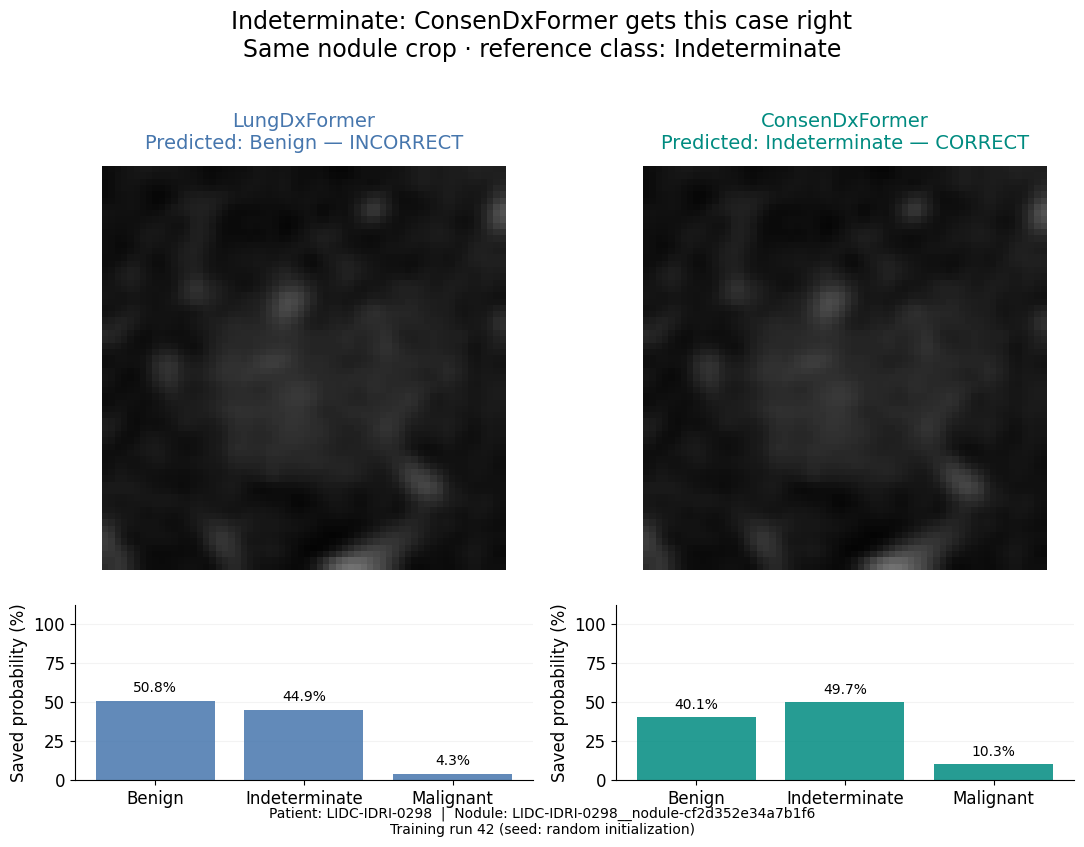

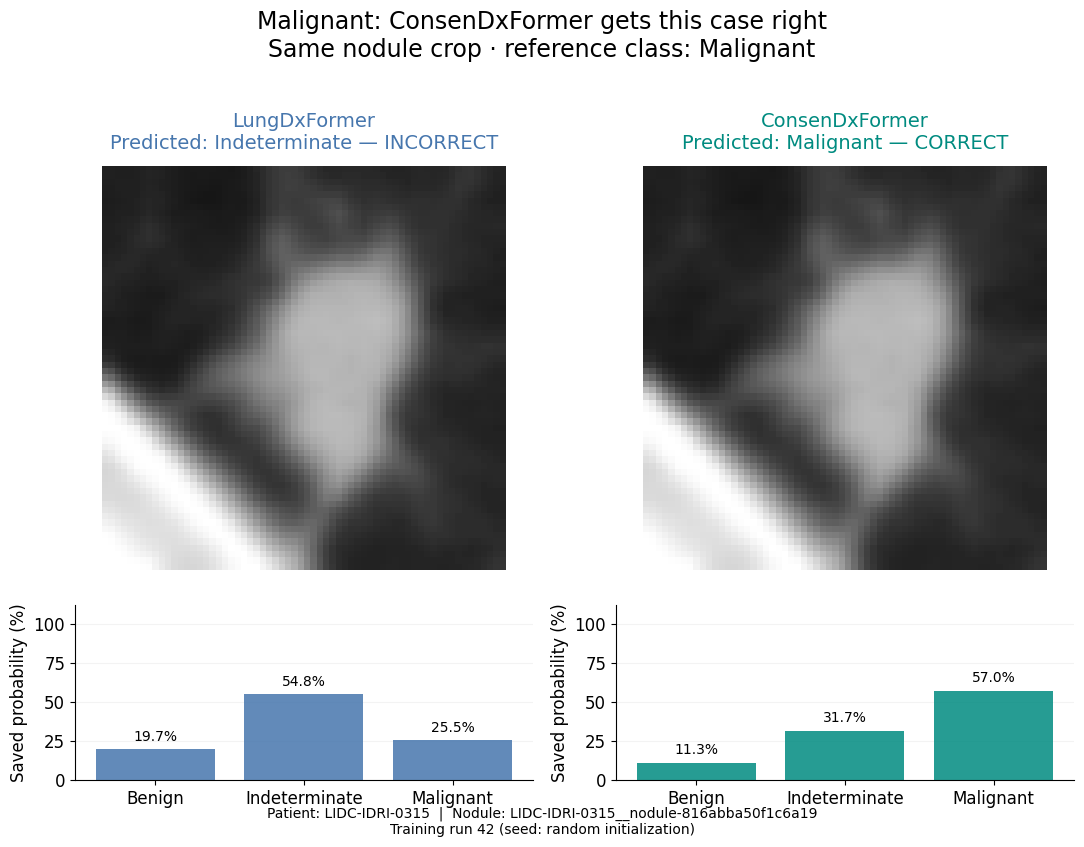

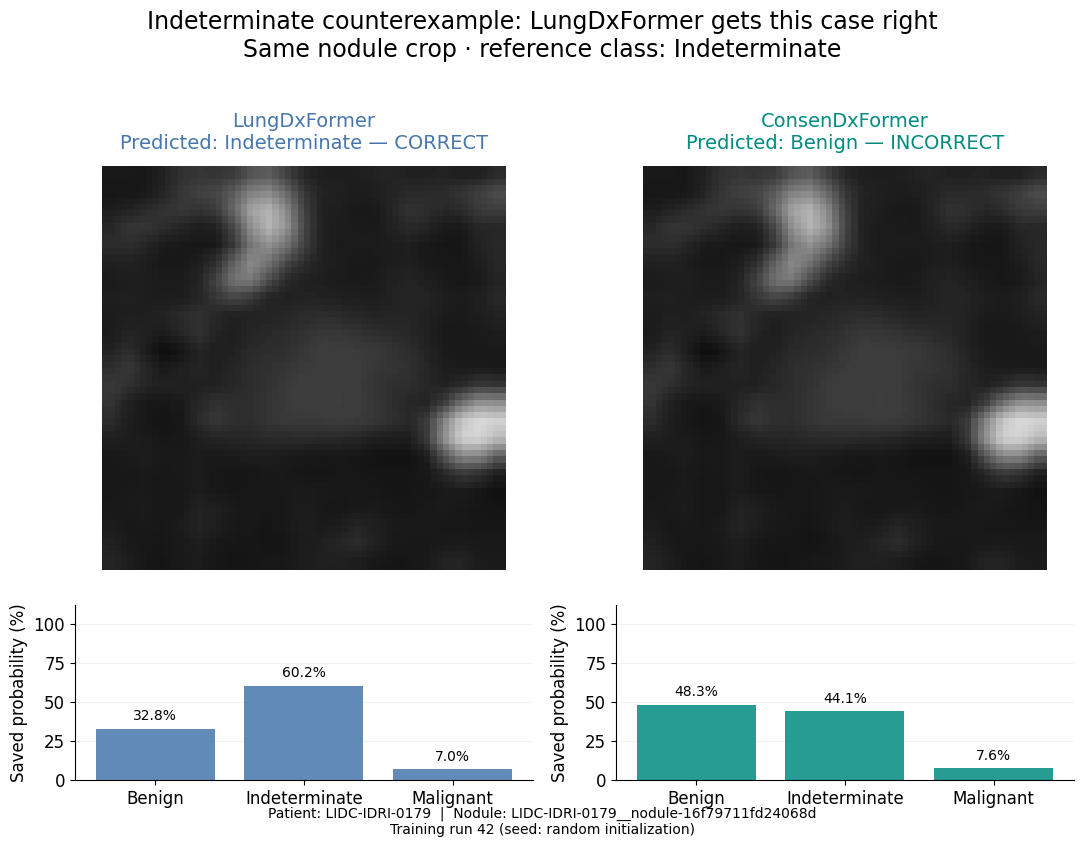

In [13]:
'''# loads the exact saved nodule image for the same patient and shows
how both models classified that exact image.

# IMPORTANT: The code checks patient, scan, nodule ID, test split, label, file type, 
and file hash so the image cannot be silently replaced by another case.
'''
def exact_input(row,model,seed):
    m=metadata[model,seed]
    selected=m.copy()
    for k in IDS: selected=selected[selected[k].astype(str)==str(row[k])]
    assert len(selected)==1, 'Image metadata identity is missing or ambiguous.'
    rec=selected.iloc[0]
    assert rec['split']=='test'
    label_col='label' if 'label' in rec.index else 'true_class'
    assert rec[label_col]==row.true_class_B1, 'Image reference label mismatch.'
    path=Path(str(rec.image_path))
    assert path.is_absolute(), 'Relative image path requires explicit original-base review.'
    assert path.suffix.lower()=='.npy' and path.is_file(), 'Use the recorded NPY nodule crop; no CT-slice search.'
    for key in ('image_sha256','image_path_sha256'):
        if key in rec.index and pd.notna(rec[key]): assert sha(path)==str(rec[key])
    x=np.load(path,allow_pickle=False).astype(np.float32)
    if x.ndim==3 and x.shape[0]==1: x=x[0]
    if x.ndim==3 and x.shape[-1]==1: x=x[...,0]
    assert x.ndim==2 and np.isfinite(x).all(), 'Unexpected crop shape or values.'
    import cv2
    x=cv2.resize(x,(64,64),interpolation=cv2.INTER_LINEAR)
    if x.max()>1: x=x/255.
    return x,path

ranked=metrics[metrics.model=='ConsenDxFormer'].sort_values(['Indeterminate F1','Indeterminate recall','seed'],ascending=[False,False,True])
DISPLAY_SEED=int(ranked.iloc[0]['seed'])
card('Selected example run',f'Training run {DISPLAY_SEED} (seed = random initialization number). Chosen for the highest indeterminate F1 of the three ConsenDxFormer runs; this is a post-hoc illustration.')
J=joined[DISPLAY_SEED].sort_values(IDS).reset_index(drop=True)

def show_case(row,title):
    image,path=exact_input(row,'B1',DISPLAY_SEED)
    same,second_path=exact_input(row,'ConsenDxFormer',DISPLAY_SEED)
    assert np.array_equal(image,same), 'Recorded model inputs differ; stop same-image comparison.'
    fig,axes=plt.subplots(2,2,figsize=(11,8),gridspec_kw={'height_ratios':[2.3,1]})
    for col,(model,suffix) in enumerate([('B1','B1'),('ConsenDxFormer','Consen')]):
        predicted=row['predicted_class_'+suffix]; reference=row.true_class_B1
        correct=predicted==reference
        axes[0,col].imshow(image,cmap='gray',vmin=0,vmax=1,interpolation='nearest'); axes[0,col].axis('off')
        axes[0,col].set_title(NAMES[model]+'\nPredicted: '+predicted.title()+' — '+('CORRECT' if correct else 'INCORRECT'),
                              color=COLORS[model],fontsize=14,pad=12)
        probs=np.array([row['prob_'+c+'_'+suffix] for c in CLASSES])*100
        bars=axes[1,col].bar([c.title() for c in CLASSES],probs,color=COLORS[model],alpha=.85)
        axes[1,col].bar_label(bars,labels=[f'{v:.1f}%' for v in probs],padding=4,fontsize=10)
        axes[1,col].set(ylim=(0,112),ylabel='Saved probability (%)')
        axes[1,col].grid(axis='y',alpha=.15); axes[1,col].set_axisbelow(True)
    fig.suptitle(title+'\nSame nodule crop · reference class: '+row.true_class_B1.title(),fontsize=17,y=1.02)
    fig.text(.5,-.01,'Patient: '+row.patient_id+'  |  Nodule: '+row.nodule_id+'\nTraining run '+str(DISPLAY_SEED)+' (seed: random initialization)',ha='center',fontsize=10)
    plt.tight_layout(h_pad=2.2); plt.show()

for c in ('indeterminate','benign','malignant'):
    wins=J[(J.true_class_B1==c)&(J.predicted_class_Consen==c)&(J.predicted_class_B1!=c)]
    if len(wins):
        show_case(wins.iloc[0],c.title()+': ConsenDxFormer gets this case right')
    else:
        card(c.title()+' examples','No ConsenDxFormer-only correct case exists in the selected run for this class. No example is invented.')

# One counterexample makes the selected-run presentation honest about its limits.
counter=J[(J.true_class_B1=='indeterminate')&(J.predicted_class_B1=='indeterminate')&(J.predicted_class_Consen!='indeterminate')]
if len(counter):
    show_case(counter.iloc[0],'Indeterminate counterexample: LungDxFormer gets this case right')
else:
    card('Indeterminate counterexample','There is no LungDxFormer-only correct indeterminate case in this selected run.')

## 5. Class-by-class result: which model has the higher score?

This section compares F1 separately for benign, indeterminate, and malignant nodules. F1 considers both finding the class and avoiding wrong predictions of that class.


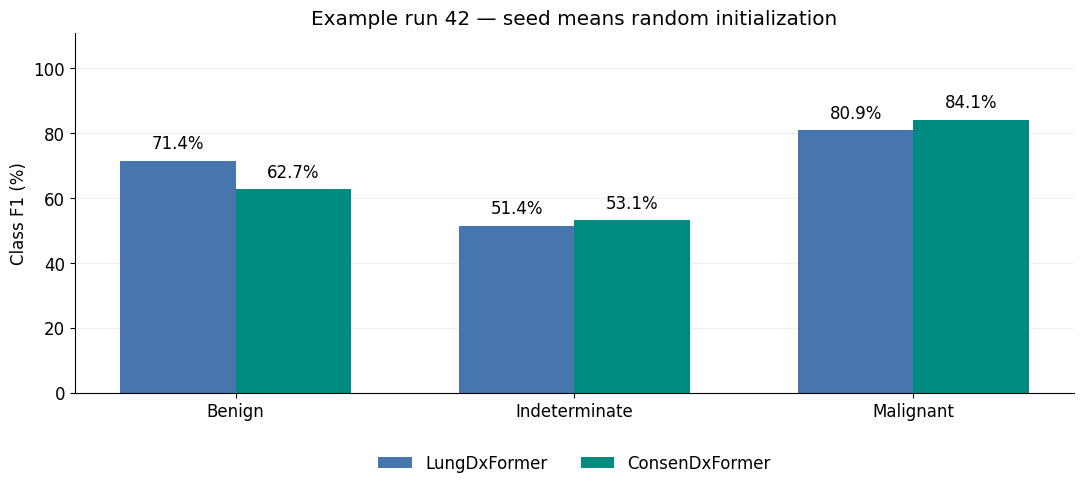

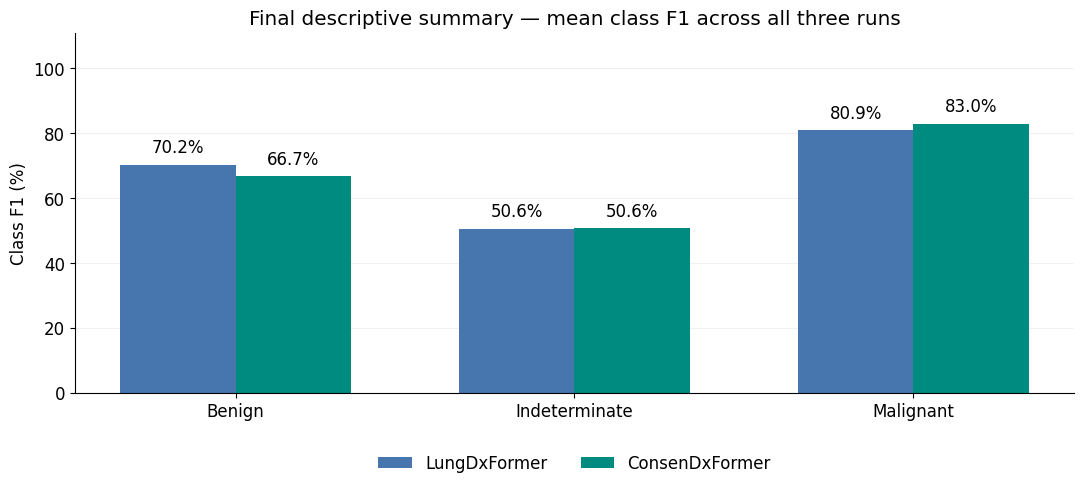

Class,LungDxFormer F1,ConsenDxFormer F1,Higher average F1,Consen minus Lung
Benign,70.2%,66.7%,LungDxFormer,-3.5 percentage points
Indeterminate,50.6%,50.6%,ConsenDxFormer,+0.1 percentage points
Malignant,80.9%,83.0%,ConsenDxFormer,+2.0 percentage points


In [7]:
'''
# This cell draws class-by-class F1 charts. First it shows the selected example run, 
then it averages all three runs and reports which model has the higher descriptive F1
for each class.

# IMPORTANT: “Higher” here means a higher measured F1, not automatically a statistically
proven win.
'''
def plot_class_f1(frame,title):
    vals=frame.pivot(index='class',columns='model',values='f1').reindex(CLASSES)[['B1','ConsenDxFormer']]*100
    fig,ax=plt.subplots(figsize=(11,5.1)); x=np.arange(3); width=.34
    for k,m in enumerate(['B1','ConsenDxFormer']):
        bars=ax.bar(x+(k-.5)*width,vals[m].to_numpy(),width,color=COLORS[m],label=NAMES[m])
        ax.bar_label(bars,labels=[f'{v:.1f}%' for v in vals[m]],padding=6)
    ax.set(xticks=x,xticklabels=[c.title() for c in CLASSES],ylim=(0,111),ylabel='Class F1 (%)',title=title)
    ax.legend(loc='upper center',bbox_to_anchor=(.5,-.13),ncol=2,frameon=False); ax.grid(axis='y',alpha=.18); ax.set_axisbelow(True)
    plt.tight_layout(); plt.show()
    return vals

single=per_class[per_class.seed==DISPLAY_SEED]
plot_class_f1(single,f'Example run {DISPLAY_SEED} — seed means random initialization')
mean_class=per_class.groupby(['class','model'],as_index=False)['f1'].mean()
final_values=plot_class_f1(mean_class,'Final descriptive summary — mean class F1 across all three runs')
winners=[]
for c,row in final_values.iterrows():
    a=float(row['B1']); b=float(row['ConsenDxFormer'])
    higher='Tie' if np.isclose(a,b,atol=1e-10,rtol=0) else ('ConsenDxFormer' if b>a else 'LungDxFormer')
    winners.append({'Class':c.title(),'LungDxFormer F1':f'{a:.1f}%','ConsenDxFormer F1':f'{b:.1f}%',
                    'Higher average F1':higher,'Consen minus Lung':f'{b-a:+.1f} percentage points'})
nice_table(pd.DataFrame(winners),'Class winners by observed average F1','These are descriptive winners on this saved test set. They do not establish statistical superiority, external robustness, or clinical benefit.')

## 6. Progress since the last meeting

The progress since then is stronger evidence, diagnosis of weaknesses, and preparation of a separate improvement study. No new accuracy gain has been measured yet.

---
No new ConsenDxFormer has been trained since the earlier Stage A model. The new work is checking the evidence, understanding weaknesses, and planning a better v2 experiment.


In [17]:
'''
# This cell summarizes what has been completed, what possible weakness was found, 
and what is planned for Performance-v2.

# IMPORTANT: Planned v2 ideas must be trained and tested before claiming improvement.
'''
progress=[
    ('Planned in v2: two separate outputs',
     'Use one output to predict the three-class nodule result and another output to learn the doctors’ different opinions.'),

    ('Planned in v2: controlled pretraining',
     'Compare the same CNN using random weights, ImageNet weights, and RadImageNet medical-image weights to see which starting point works better.'),

]

for title,text in progress:
    card(title,text,'#008B80' if title.startswith('Completed') else '#123C50')